In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [26]:
def power_law(m, A, alpha):
    return A * m**alpha

In [27]:
job_ids = [2188349,2187497, 2187505, 2187513]  
a_planets=[1,10, 30, 50] 
masses=np.logspace(-2,-3.5, 6)

In [28]:
df_is_list = []
df_fs=[]
for job_id in job_ids:
    df_is=[]
    


    for i in range(6):
        f=f'/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Particle_Tracking/{job_id}-{i}_initial_particles.txt'
        df=pd.read_csv(f, header=None)
        df.columns=['a','e','particle_id']

        df_is.append(df)
    f=f'/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results/{job_id}_ejection_results.txt'
    df=pd.read_csv(f, header=None)
    df.columns=['mass','time','result','particle_id']

    df_fs.append(df)
    df_is_list.append(df_is)

Text(0.5, 0.01, '$a_p/a - 1$')

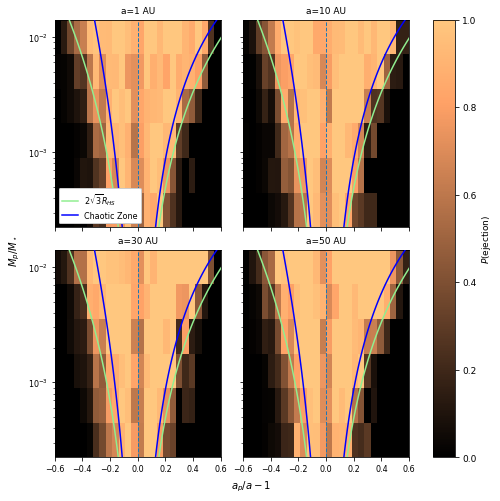

In [ ]:
cm = 1/2.54  # centimeters in inches
# fig, ax = plt.subplots(1, 1, tight_layout=False,figsize=(8.7*cm,8.7*cm),sharex=False,sharey=False
#                        ,gridspec_kw={'hspace': 0.35, 'wspace': 0.3})
fig, axes = plt.subplots(
    2, 2,
    figsize=(2*8.7*cm, 2*8.7*cm),
    sharey=True,
    sharex=True,
    layout='constrained'
)

mass_values = masses.copy()
# fig, axes = plt.subplots(
#     2, 2,
#     figsize=(12, 9),
#     sharex=True,
#     sharey=True,
#     layout='constrained'
# )

axes = axes.ravel()

for i, (ax, df_is, a_planet, df_f) in enumerate(zip(axes, df_is_list, a_planets, df_fs)):
        


    # ============================================================
    # REDEFINED HERE
    # ============================================================

    #a_planet = 10.0

    # Your variable `masses` contains log10(mass).
    # df_f["mass"] contains the actual mass.
    mass_values = masses

    # Keep the same number of bins that you previously had in a.


    # Your chosen coordinate:
    #
    #     x = a_planet / a - 1
    #
    # Determine the x-range corresponding to the old a-range.

    n_bins = 26          # MUST be odd
    x_max = 0.6          # choose desired extent

    x_edges = np.linspace(
        -x_max,
        x_max,
        n_bins + 1
    )

    x_centers = 0.5 * (x_edges[:-1] + x_edges[1:])


    # ============================================================
    # CALCULATE EJECTION PROBABILITY IN EACH x BIN
    # ============================================================

    P = []

    for mass, df_i in zip(mass_values, df_is):

        # Results corresponding to this planet mass
        final_df = df_f[
            np.isclose(df_f["mass"], mass)
        ]

        # Particle IDs that eventually ejected
        ejected_ids = final_df.loc[
            final_df["result"] == "Ejected",
            "particle_id"
        ].unique()

        df = df_i.copy()

        # Identify ejected particles
        df["ejected"] = df["particle_id"].isin(ejected_ids)

        # --------------------------------------------------------
        # IMPORTANT CHANGE:
        # Transform EACH PARTICLE to x before histogramming.
        # --------------------------------------------------------
        df["x"] = a_planet / df["a"] - 1


        # Number of all particles initially in each x bin
        N_all, _ = np.histogram(
            df["x"],
            bins=x_edges
        )

        # Number of ejected particles initially in each x bin
        N_ej, _ = np.histogram(
            df.loc[df["ejected"], "x"],
            bins=x_edges
        )
        

        # Probability of ejection
        p = np.divide(
            N_ej,
            N_all,
            out=np.full_like(
                N_ej,
                np.nan,
                dtype=float
            ),
            where=N_all > 0
        )

        P.append(p)


    P = np.asarray(P)


    # ============================================================
    # SORT MASSES
    # ============================================================

    # pcolormesh is easiest to reason about with increasing y.
    mass_order = np.argsort(mass_values)

    mass_values = mass_values[mass_order]
    P = P[mass_order, :]


    # ============================================================
    # DEFINE MASS-BIN EDGES
    # ============================================================
    #
    # The masses are logarithmically spaced, so their visual
    # boundaries should be halfway between them in log10 space.
    # ============================================================

    log_masses = np.log10(mass_values)

    log_mass_edges = np.empty(len(log_masses) + 1)

    # Interior edges
    log_mass_edges[1:-1] = 0.5 * (
        log_masses[:-1] + log_masses[1:]
    )

    # Extrapolate first and last edges
    log_mass_edges[0] = (
        log_masses[0]
        - 0.5 * (log_masses[1] - log_masses[0])
    )

    log_mass_edges[-1] = (
        log_masses[-1]
        + 0.5 * (log_masses[-1] - log_masses[-2])
    )

    mass_edges = 10**log_mass_edges


    # ============================================================
    # PLOT
    # ============================================================




    mesh = ax.pcolormesh(
        x_edges,
        mass_edges,
        P,
        shading="flat",
        vmin=0,
        vmax=1,
        cmap="copper"
    )

    ax.set_yscale("log")

    ax.axvline(
        0,
        linestyle="--",
        linewidth=1
    )



    

    plot_masses=np.logspace(-1, -4, 100)

    HS_values=a_planet*(plot_masses/(3*(1+plot_masses)))**(1/3)
    inv_HS_values_inner=a_planet/(a_planet-HS_values)-1
    inv_HS_values_outer=a_planet/(a_planet+HS_values)-1

    CZ_values_inner=1.2*(plot_masses**0.28*a_planet)
    CZ_values_outer=1.7*(plot_masses**0.31*a_planet)

    inv_CZ_values_inner=a_planet/(a_planet-CZ_values_inner)-1
    inv_CZ_values_outer=a_planet/(a_planet+CZ_values_outer)-1

    A_inner = 3.729132931366645
    alpha_inner = 0.14939347354180882

    A_outer = 34.508406515008886
    alpha_outer = 0.32060397131882085
    fit_outer=a_planet+a_planet*power_law(plot_masses, A_outer, alpha_outer)/5
    fit_inner=a_planet-a_planet*power_law(plot_masses, A_inner, alpha_inner)/5

    inv_fit_outer=a_planet/(fit_outer)-1
    inv_fit_inner=a_planet/(fit_inner)-1

    ax.plot(2*np.sqrt(3)*inv_HS_values_inner,plot_masses,  color='#90EE90', label=r'$2\sqrt{3}R_{HS}$', zorder=10)
    ax.plot(2*np.sqrt(3)*inv_HS_values_outer,plot_masses,  color='#90EE90', zorder=10)
    ax.plot(inv_CZ_values_inner,plot_masses,  color='blue', label='Chaotic Zone', zorder=10)
    ax.plot(inv_CZ_values_outer,plot_masses,  color='blue', zorder=10)
    # ax.plot(inv_fit_inner,plot_masses,  color='green', zorder=10)
    # ax.plot(inv_fit_outer,plot_masses,  color='green', label='Power Law Fit', zorder=10)

    ax.set_xlim(-0.6,0.6)
    ax.set_ylim(mass_edges.min(),mass_edges.max())
    ax.set_title(f'a={a_planet} AU', fontsize=9)
    ax.tick_params(labelsize=8)
leg=axes[0].legend(loc='lower left', framealpha=1, fontsize=8)
leg.set_zorder(15)
cbar = fig.colorbar(mesh, ax=axes )
cbar.set_label(r"$P(\mathrm{ejection})$", fontsize=9)
cbar.ax.tick_params(labelsize=9)
fig.supylabel(r"$M_p/M_\star$", fontsize=10)
fig.supxlabel(r"$a_p/a - 1$", fontsize=10)

#plt.savefig('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Visualizations/four_panel_P_heatmap.png',bbox_inches='tight',facecolor='white', dpi=500)

In [30]:
df_is=df_is_list[0]
a_planet=1
df_f=df_fs[0]

In [31]:
masses=np.logspace(-2,-3.5, 6)

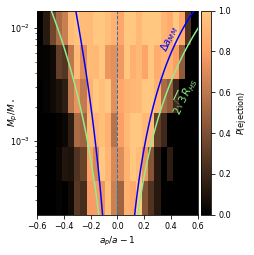

In [95]:
cm = 1/2.54  # centimeters in inches
# fig, ax = plt.subplots(1, 1, tight_layout=False,figsize=(8.7*cm,8.7*cm),sharex=False,sharey=False
#                        ,gridspec_kw={'hspace': 0.35, 'wspace': 0.3})
fig, ax = plt.subplots(
    1, 1,
    figsize=(8.7*cm, 8.7*cm),
    layout='constrained'
)

n_bins = 26          # MUST be odd
x_max = 0.6          # choose desired extent

x_edges = np.linspace(
    -x_max,
    x_max,
    n_bins + 1
)
mass_values = masses.copy()
x_centers = 0.5 * (x_edges[:-1] + x_edges[1:])


# ============================================================
# CALCULATE EJECTION PROBABILITY IN EACH x BIN
# ============================================================

P = []

for mass, df_i in zip(mass_values, df_is):

    # Results corresponding to this planet mass
    final_df = df_f[
        np.isclose(df_f["mass"], mass)
    ]

    # Particle IDs that eventually ejected
    ejected_ids = final_df.loc[
        final_df["result"] == "Ejected",
        "particle_id"
    ].unique()

    df = df_i.copy()

    # Identify ejected particles
    df["ejected"] = df["particle_id"].isin(ejected_ids)

    # --------------------------------------------------------
    # IMPORTANT CHANGE:
    # Transform EACH PARTICLE to x before histogramming.
    # --------------------------------------------------------
    df["x"] = a_planet / df["a"] - 1


    # Number of all particles initially in each x bin
    N_all, _ = np.histogram(
        df["x"],
        bins=x_edges
    )

    # Number of ejected particles initially in each x bin
    N_ej, _ = np.histogram(
        df.loc[df["ejected"], "x"],
        bins=x_edges
    )
    

    # Probability of ejection
    p = np.divide(
        N_ej,
        N_all,
        out=np.full_like(
            N_ej,
            np.nan,
            dtype=float
        ),
        where=N_all > 0
    )

    P.append(p)


P = np.asarray(P)


# ============================================================
# SORT MASSES
# ============================================================

# pcolormesh is easiest to reason about with increasing y.
mass_order = np.argsort(mass_values)

mass_values = mass_values[mass_order]
P = P[mass_order, :]


# ============================================================
# DEFINE MASS-BIN EDGES
# ============================================================
#
# The masses are logarithmically spaced, so their visual
# boundaries should be halfway between them in log10 space.
# ============================================================

log_masses = np.log10(mass_values)

log_mass_edges = np.empty(len(log_masses) + 1)

# Interior edges
log_mass_edges[1:-1] = 0.5 * (
    log_masses[:-1] + log_masses[1:]
)

# Extrapolate first and last edges
log_mass_edges[0] = (
    log_masses[0]
    - 0.5 * (log_masses[1] - log_masses[0])
)

log_mass_edges[-1] = (
    log_masses[-1]
    + 0.5 * (log_masses[-1] - log_masses[-2])
)

mass_edges = 10**log_mass_edges


# ============================================================
# PLOT
# ============================================================




mesh = ax.pcolormesh(
    x_edges,
    mass_edges,
    P,
    shading="flat",
    vmin=0,
    vmax=1,
    cmap="copper"
)

ax.set_yscale("log")

ax.axvline(
    0,
    linestyle="--",
    linewidth=1
)





plot_masses=np.logspace(-1, -4, 100)

HS_values=a_planet*(plot_masses/(3*(1+plot_masses)))**(1/3)
inv_HS_values_inner=a_planet/(a_planet-HS_values)-1
inv_HS_values_outer=a_planet/(a_planet+HS_values)-1

CZ_values_inner=1.2*(plot_masses**0.28*a_planet)
CZ_values_outer=1.7*(plot_masses**0.31*a_planet)

inv_CZ_values_inner=a_planet/(a_planet-CZ_values_inner)-1
inv_CZ_values_outer=a_planet/(a_planet+CZ_values_outer)-1

A_inner = 3.729132931366645
alpha_inner = 0.14939347354180882

A_outer = 34.508406515008886
alpha_outer = 0.32060397131882085
fit_outer=a_planet+a_planet*power_law(plot_masses, A_outer, alpha_outer)/5
fit_inner=a_planet-a_planet*power_law(plot_masses, A_inner, alpha_inner)/5

inv_fit_outer=a_planet/(fit_outer)-1
inv_fit_inner=a_planet/(fit_inner)-1

ax.plot(2*np.sqrt(3)*inv_HS_values_inner,plot_masses,  color='#90EE90', label=r'$2\sqrt{3}R_{HS}$', zorder=10)
ax.plot(2*np.sqrt(3)*inv_HS_values_outer,plot_masses,  color='#90EE90', zorder=10)
ax.plot(inv_CZ_values_inner,plot_masses,  color='blue', label='Chaotic Zone', zorder=10)
ax.plot(inv_CZ_values_outer,plot_masses,  color='blue', zorder=10)
# ax.plot(inv_fit_inner,plot_masses,  color='green', zorder=10)
# ax.plot(inv_fit_outer,plot_masses,  color='green', label='Power Law Fit', zorder=10)

ax.set_xlim(-0.6,0.6)
ax.set_ylim(mass_edges.min(),mass_edges.max())
ax.tick_params(labelsize=8)


cbar = fig.colorbar(mesh, ax=ax , pad=-0.02)
cbar.set_label(r"$P(\mathrm{ejection})$", fontsize=8)
cbar.ax.tick_params(labelsize=8)

ax.annotate(
        r"$\Delta a_{MM}$",
        xy=(0.3,10**(-2.1)),
        color='blue',
        fontsize=10,
        va="center",
        zorder=25,
        rotation=65
    )
# ax.annotate(
#         r"$\Delta a_{MM}$",
#         xy=(-0.3,10**(-2.1)),
#         color='blue',
#         fontsize=10,
#         va="center",
#         zorder=25,
#         rotation=-65
#     )
# ax.annotate(
#         r"$R_{CZ}$",
#         xy=(-0.3,10**(-2.1)),
#         color='blue',
#         fontsize=10,
#         va="center",
#         zorder=25,
#         rotation=-65
#     )
ax.annotate(
        r"$2\sqrt{3} R_{HS}$",
        xy=(0.37,10**(-2.6)),
        color='#90EE90',
        fontsize=10,
        va="center",
        zorder=25,
        rotation=65
    )
ax.set_ylabel(r"$M_p/M_\star$", fontsize=9, labelpad=-10)
ax.set_xlabel(r"$a_p/a - 1$", fontsize=9)

plt.savefig('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Visualizations/one_panel_energy_heatmap.png', facecolor='white',bbox_inches='tight',dpi=600)